# Dynamic Landscapes: In-Class Activity


**Based on:** De Jong (2006), *Evolutionary Computation: A Unified Approach*, Section 7.2

## Setup
Run this cell first to initialize the landscape, fitness evaluation functions, helper plotting, and tracking functions.

In [1]:
#@title Setup: run this cell first (no need to edit)
import numpy as np
import matplotlib.pyplot as plt

# ---------- Landscape ----------
# Fitness is distance to a single peak: 0 is perfect, more negative is worse.
def fitness(x, peak):
    return -np.abs(x - peak)

def peak_position(gen, landscape, change_gen, speed, jump_to, period):
    """Where the peak is at a given generation."""
    if landscape == "static" or gen <= change_gen:
        return 0.0
    if landscape == "drift":          # peak keeps moving at a constant speed
        return speed * (gen - change_gen)
    if landscape == "abrupt":         # peak jumps once and stays there
        return jump_to
    if landscape == "oscillate":      # peak flips between 0 and jump_to every `period` generations
        return jump_to if ((gen - change_gen - 1) // period) % 2 == 0 else 0.0
    raise ValueError(landscape)

# ---------- GA (truncation selection, mutation only) ----------
def run_ga(peaks, pop_size=20, top_k=5, mutation_rate=0.2, mutation_size=1.0,
           immigrants=0.0, hypermutation=False, drop_threshold=0.05, hyper_gens=3):
    pop = np.random.uniform(-5, 5, pop_size)
    best, spread = [], []
    prev_best, hyper_left = None, 0
    for peak in peaks:
        fit = fitness(pop, peak)
        best.append(fit.max())
        spread.append(pop.std())          # population diversity

        # Triggered hypermutation: if best fitness suddenly drops, mutate harder for a few gens
        if hypermutation and prev_best is not None and prev_best - fit.max() > drop_threshold:
            hyper_left = hyper_gens
        prev_best = fit.max()

        rate, size = (1.0, mutation_size * 3) if hyper_left > 0 else (mutation_rate, mutation_size)
        hyper_left = max(0, hyper_left - 1)

        # Selection: copy from the top_k best individuals
        top = np.argsort(fit)[-top_k:]
        parents = pop[top]
        pop = np.random.choice(parents, pop_size)

        # Mutation
        mutate = np.random.rand(pop_size) < rate
        pop += mutate * np.random.normal(0, size, pop_size)

        # Random Immigrants (replace some individuals with brand new random ones)
        if immigrants > 0:
            num_imm = int(immigrants * pop_size)
            pop[:num_imm] = np.random.uniform(-5, 5, num_imm)

    return np.array(best), np.array(spread)

# ---------- ES (1,20) with self-adaptive step size sigma ----------
def run_es(peaks, sigma_init=1.0, n_children=20, tau=0.15, sigma_min=0.01, sigma_max=2.0):
    pop = np.random.uniform(-5, 5, n_children)
    sigmas = np.full(n_children, sigma_init)
    best, sigma_hist = [], []
    for peak in peaks:
        fit = fitness(pop, peak)
        i = np.argmax(fit)                      # best child becomes the parent
        best.append(fit[i])
        sigma_hist.append(sigmas[i])
        # each new child gets a mutated copy of the parent's sigma (self-adaptation)
        sigmas = np.clip(sigmas[i] * np.exp(np.random.normal(0, tau, n_children)), sigma_min, sigma_max)
        pop = pop[i] + np.random.normal(0, sigmas)
    return np.array(best), np.array(sigma_hist)

# ---------- Helpers ----------
def make_peaks(generations, landscape, change_gen, speed, jump_to, period):
    return [peak_position(g, landscape, change_gen, speed, jump_to, period) for g in range(generations)]

def average(func, runs, *args, **kwargs):
    best_runs, metric_runs = [], []
    for _ in range(runs):
        best, metric = func(*args, **kwargs)
        best_runs.append(best)
        metric_runs.append(metric)
    return np.mean(best_runs, axis=0), np.mean(metric_runs, axis=0)

def shade(ax, change_gen, generations, landscape):
    ax.axvspan(0, change_gen, color="green", alpha=0.05, label="Before change")
    ax.axvspan(change_gen, generations-1, color="red", alpha=0.05, label="After change")
    ax.axvline(change_gen, color="gray", ls="--", alpha=0.7)

def summary(label, best, change_gen):
    before = best[:change_gen].mean()
    after = best[change_gen:].mean()
    print(f"{label:<14} avg best fitness  before change: {before: .3f}   after change: {after: .3f}")

## Part 1: Predict & run (~6 min)

Your instructions: e.g., change only one setting, predict first, then run

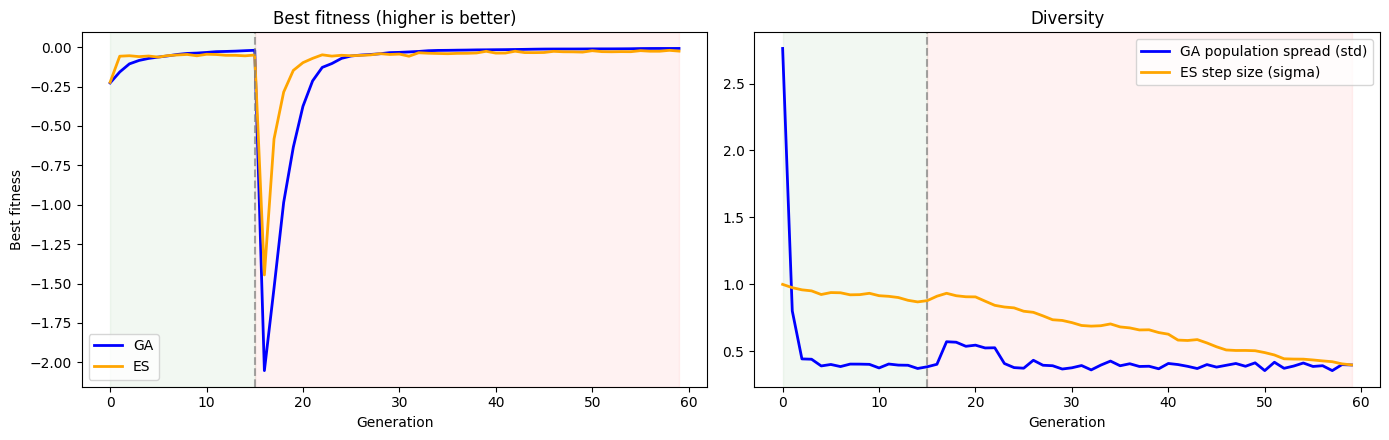

GA             avg best fitness  before change: -0.068   after change: -0.151
ES             avg best fitness  before change: -0.064   after change: -0.090


In [4]:
#@title Part 1: change ONE setting, then run
landscape = "abrupt"  #@param ["static", "drift", "abrupt", "oscillate"]
speed = 0.52  #@param {type:"slider", min:0.0, max:1.0, step:0.02}
jump_to = 3.0  #@param {type:"slider", min:0.5, max:5.0, step:0.5}
period = 10  #@param {type:"slider", min:2, max:30, step:1}
change_gen = 15  #@param {type:"slider", min:5, max:40, step:1}
ga_top_k = 5  #@param {type:"slider", min:1, max:20, step:1}
es_sigma_init = 1.0  #@param {type:"slider", min:0.1, max:5.0, step:0.1}

generations = 60
runs = 100

land = dict(landscape=landscape, change_gen=change_gen, speed=speed, jump_to=jump_to, period=period)
peaks = make_peaks(generations, **land)

ga_best, ga_spread = average(run_ga, runs, peaks, top_k=ga_top_k)
es_best, es_sigma = average(run_es, runs, peaks, sigma_init=es_sigma_init)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ga_best, label="GA", color="blue", lw=2)
ax[0].plot(es_best, label="ES", color="orange", lw=2)
ax[0].set(title="Best fitness (higher is better)", xlabel="Generation", ylabel="Best fitness")
ax[0].legend()
ax[1].plot(ga_spread, label="GA population spread (std)", color="blue", lw=2)
ax[1].plot(es_sigma, label="ES step size (sigma)", color="orange", lw=2)
ax[1].set(title="Diversity", xlabel="Generation")
ax[1].legend()
for a in ax:
    shade(a, change_gen, generations, landscape)
plt.tight_layout(); plt.show()

summary("GA", ga_best, change_gen)
summary("ES", es_best, change_gen)

Instructions: Assign each pair a landscape type, and briefly describe the goal


## Part 2: Fix the GA (~7 min)

Assign each pair a landscape type, and briefly describe the goal.

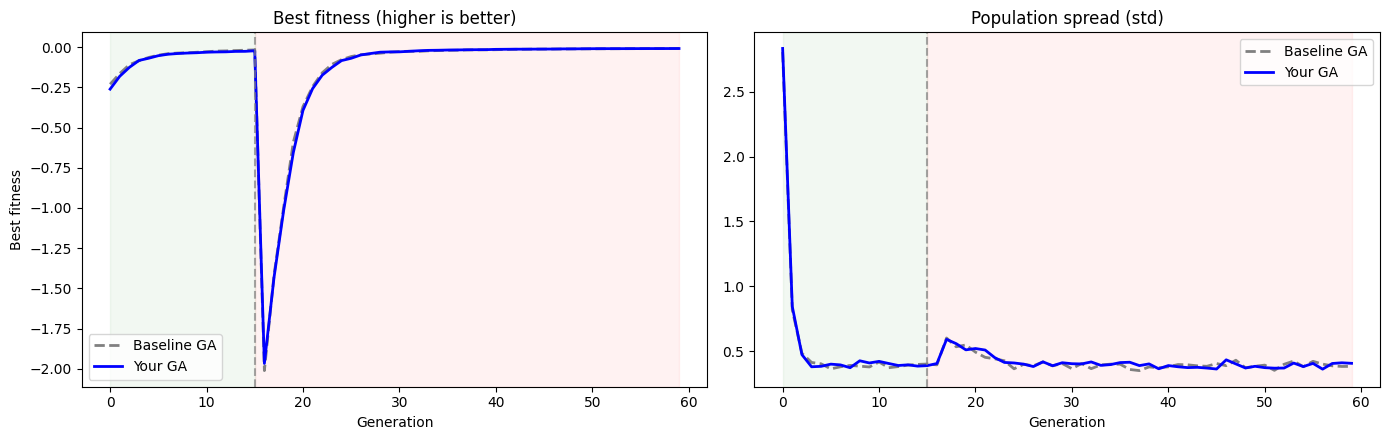

Baseline GA    avg best fitness  before change: -0.064   after change: -0.147
Your GA        avg best fitness  before change: -0.071   after change: -0.150


In [3]:
#@title Part 2: give the GA a diversity tool, then compare it to the baseline
landscape = "abrupt"  #@param ["drift", "abrupt", "oscillate"]
speed = 0.2  #@param {type:"slider", min:0.0, max:1.0, step:0.02}
jump_to = 3.0  #@param {type:"slider", min:0.5, max:5.0, step:0.5}
period = 10  #@param {type:"slider", min:2, max:30, step:1}
#@markdown ---
#@markdown **Your diversity tools** (De Jong 7.2.5)
top_k = 5  #@param {type:"slider", min:1, max:20, step:1}
immigrants = 0.0  #@param {type:"slider", min:0.0, max:0.5, step:0.05}
hypermutation = False  #@param {type:"boolean"}
change_gen = 15
generations = 60
runs = 100

land = dict(landscape=landscape, change_gen=change_gen, speed=speed, jump_to=jump_to, period=period)
peaks = make_peaks(generations, **land)
base_best, base_spread = average(run_ga, runs, peaks)
mine_best, mine_spread = average(run_ga, runs, peaks, top_k=top_k,
                                 immigrants=immigrants, hypermutation=hypermutation)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(base_best, label="Baseline GA", color="gray", lw=2, ls="--")
ax[0].plot(mine_best, label="Your GA", color="blue", lw=2)
ax[0].set(title="Best fitness (higher is better)", xlabel="Generation", ylabel="Best fitness")
ax[0].legend()
ax[1].plot(base_spread, label="Baseline GA", color="gray", lw=2, ls="--")
ax[1].plot(mine_spread, label="Your GA", color="blue", lw=2)
ax[1].set(title="Population spread (std)", xlabel="Generation")
ax[1].legend()
for a in ax:
    shade(a, change_gen, generations, landscape)
plt.tight_layout(); plt.show()
summary("Baseline GA", base_best, change_gen)
summary("Your GA", mine_best, change_gen)

## Part 3: Share out (~5 min)

**Report:** your landscape, your tool, and your GA's *avg best fitness after change* compared to the baseline.

| Pair | Landscape | Tool(s) | Baseline after | Ours after |
|---|---|---|---|---|
| | | | | |

